# HW2 Part 2: single stock risk report

Risk report for one ticker over one date range, from `ohlc_hw_cleaned`. `03_run_all_stocks.py` runs it with papermill for every ticker.

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import display
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

%matplotlib inline

TRADING_DAYS, VOL_WINDOW, MA_WINDOW = 252, 20, 50
GREEN, RED, GRAY, BLUE, DARK = '#2e7d32', '#c62828', '#9e9e9e', '#1f4e79', '#37474f'

## 1. Parameters

This cell has the `parameters` tag.

In [2]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # written by 01_data_cleaning.ipynb

In [3]:
# Parameters
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"


## 2. Data

In [4]:
database = Path(db_path)
if not database.is_file():
    raise FileNotFoundError(f'{database} not found, run 01_data_cleaning.ipynb first')
if pd.Timestamp(start_date) > pd.Timestamp(end_date):
    raise ValueError(f'start_date {start_date} is after end_date {end_date}')

query = """
    SELECT ts, open, high, low, close, adj_close, volume FROM ohlc_hw_cleaned
    WHERE ticker = ? AND ts BETWEEN ? AND ? ORDER BY ts
"""
with closing(sqlite3.connect(f'{database.resolve().as_uri()}?mode=ro', uri=True)) as conn:
    prices = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date), parse_dates=['ts'], index_col='ts')

if len(prices) < VOL_WINDOW + 1:
    raise ValueError(f'{ticker}: {len(prices)} prices between {start_date} and {end_date}, '
                     f'at least {VOL_WINDOW + 1} are needed for {VOL_WINDOW} returns')

first_date, last_date = prices.index[0], prices.index[-1]
print(f'{ticker} from {start_date} to {end_date}: {len(prices)} trading days')
print(f'First observation: {first_date:%Y-%m-%d}, last observation: {last_date:%Y-%m-%d}')
display(prices.head(3))
display(prices.tail(3))

AAPL from 2024-06-01 to 2024-11-30: 97 trading days
First observation: 2024-06-03, last observation: 2024-10-18


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,192.90,194.99,192.52,194.03,193.81,50080539
2024-06-04,194.64,195.32,193.03,194.35,194.13,47471445
2024-06-05,195.40,196.90,194.87,195.87,195.64,54156785


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240
2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810
2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281


## 3. Risk metrics

All metrics use the adjusted close and daily log returns. `calculate_max_drawdown` keeps the name of the assignment but returns the drawdown on each date; the maximum drawdown is its minimum.

In [5]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Daily log returns log(p_t / p_{t-1}); the first value is NaN."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Annualized rolling volatility: std of the last `window` returns times sqrt(252), NaN before a full window."""
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Drawdown on each date: (price - running peak) / running peak."""
    peak = prices.cummax()
    return (prices - peak) / peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Annualized Sharpe ratio (252 * mean - rf) / (sqrt(252) * std); NaN with fewer than 2 returns or zero volatility."""
    observed = returns.dropna()
    std = observed.std()
    if len(observed) < 2 or not np.isfinite(std) or np.isclose(std, 0):
        return np.nan
    return (observed.mean() * TRADING_DAYS - risk_free_rate) / (std * np.sqrt(TRADING_DAYS))


report = prices[['adj_close']].copy()
report['log_return'] = calculate_returns(report['adj_close'])
report['volatility'] = calculate_volatility(report['log_return'], VOL_WINDOW)
report['ma_50'] = report['adj_close'].rolling(MA_WINDOW).mean()
report['drawdown'] = calculate_max_drawdown(report['adj_close'])
returns = report['log_return'].dropna()
mean_volatility = report['volatility'].mean()
display(report.iloc[VOL_WINDOW - 1:VOL_WINDOW + 2])

,adj_close,log_return,volatility,ma_50,drawdown
ts,,,,,
2024-07-01,216.50,0.028675,NaN,NaN,0.0
2024-07-02,220.02,0.016128,0.335958,NaN,0.0
2024-07-03,221.29,0.005756,0.335513,NaN,0.0


## 4. Charts

Price segments are red when the 20-day volatility of their end date is above its mean over the report, green otherwise, and gray before the first estimate. The 50-day average starts once 50 prices exist.

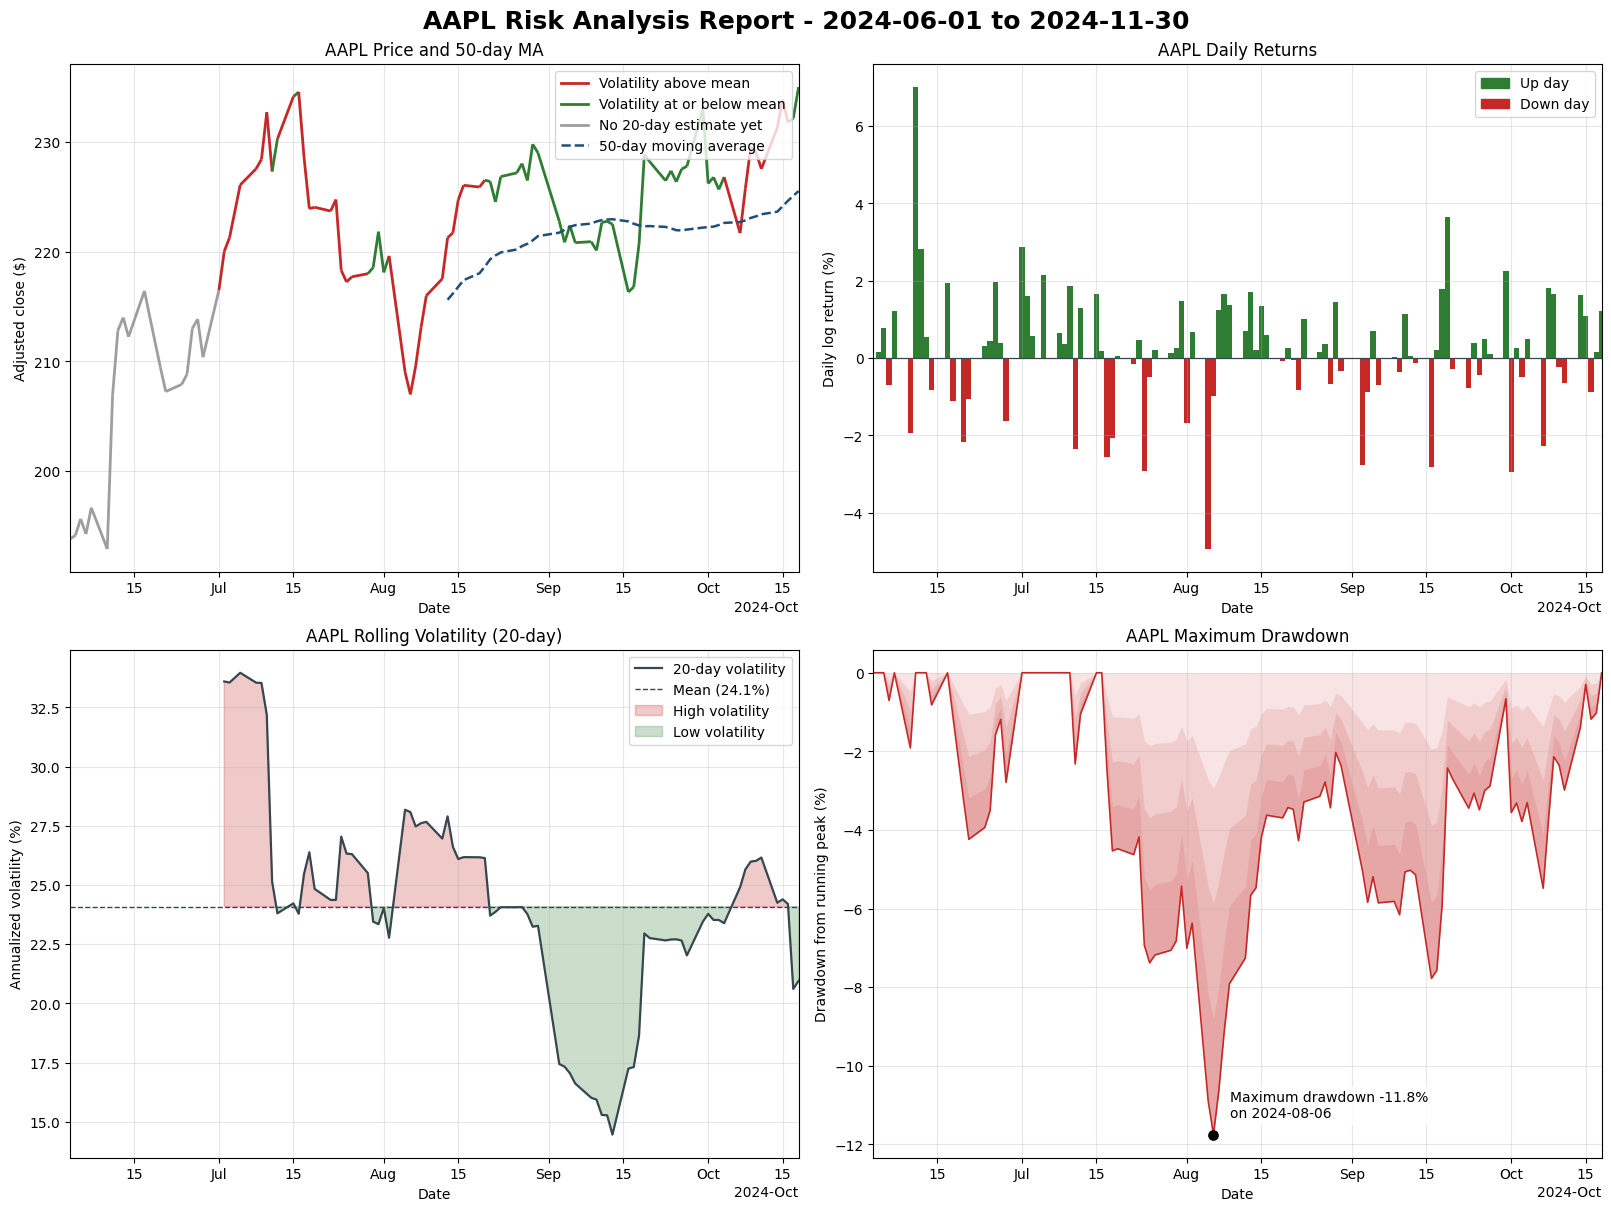

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout='constrained')
fig.suptitle(f'{ticker} Risk Analysis Report - {start_date} to {end_date}', fontsize=18, fontweight='bold')

ax = axes[0, 0]
ax.xaxis_date()
vol_at_end = report['volatility'].to_numpy()[1:]
colors = np.where(np.isnan(vol_at_end), GRAY, np.where(vol_at_end > mean_volatility, RED, GREEN))
points = np.column_stack([mdates.date2num(report.index), report['adj_close'].to_numpy()])
ax.add_collection(LineCollection(np.stack([points[:-1], points[1:]], axis=1), colors=colors, linewidths=2))
ax.autoscale_view()
ax.plot(report.index, report['ma_50'], color=BLUE, linewidth=1.8, linestyle='--')
if report['ma_50'].count() == 0:
    ax.text(0.02, 0.03, f'No 50-day average: only {len(report)} prices', transform=ax.transAxes)
ax.legend(handles=[Line2D([], [], color=RED, lw=2, label='Volatility above mean'),
                   Line2D([], [], color=GREEN, lw=2, label='Volatility at or below mean'),
                   Line2D([], [], color=GRAY, lw=2, label='No 20-day estimate yet'),
                   Line2D([], [], color=BLUE, lw=1.8, ls='--', label='50-day moving average')])
ax.set(title=f'{ticker} Price and 50-day MA', ylabel='Adjusted close ($)')

ax = axes[0, 1]
return_pct = report['log_return'] * 100
ax.bar(report.index, return_pct, width=1.0, color=np.where(return_pct >= 0, GREEN, RED))
ax.axhline(0, color=DARK, linewidth=0.9)
ax.legend(handles=[Patch(color=GREEN, label='Up day'), Patch(color=RED, label='Down day')])
ax.set(title=f'{ticker} Daily Returns', ylabel='Daily log return (%)')

ax = axes[1, 0]
vol_pct, mean_pct = report['volatility'] * 100, mean_volatility * 100
ax.plot(report.index, vol_pct, color=DARK, linewidth=1.6, label='20-day volatility')
ax.axhline(mean_pct, color=DARK, linestyle='--', linewidth=1, label=f'Mean ({mean_pct:.1f}%)')
ax.fill_between(report.index, vol_pct, mean_pct, where=vol_pct > mean_pct, interpolate=True,
                color=RED, alpha=0.25, label='High volatility')
ax.fill_between(report.index, vol_pct, mean_pct, where=vol_pct <= mean_pct, interpolate=True,
                color=GREEN, alpha=0.25, label='Low volatility')
ax.legend()
ax.set(title=f'{ticker} Rolling Volatility (20-day)', ylabel='Annualized volatility (%)')

ax = axes[1, 1]
drawdown_pct = report['drawdown'] * 100
for share in (1.0, 0.75, 0.5, 0.25):
    ax.fill_between(report.index, drawdown_pct, drawdown_pct * (1 - share), color=RED, alpha=0.12, linewidth=0)
ax.plot(report.index, drawdown_pct, color=RED, linewidth=1.2)
worst = report['drawdown'].idxmin()
right = worst > report.index[len(report) // 2]
ax.scatter([worst], [drawdown_pct[worst]], color='black', s=45, zorder=3)
ax.annotate(f'Maximum drawdown {drawdown_pct[worst]:.1f}%\non {worst:%Y-%m-%d}', (worst, drawdown_pct[worst]),
            xytext=(-12 if right else 12, 10), textcoords='offset points', ha='right' if right else 'left',
            va='bottom', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='none', alpha=0.85))
ax.set(title=f'{ticker} Maximum Drawdown', ylabel='Drawdown from running peak (%)')

for ax in axes.flat:
    ax.set_xlim(report.index[0], report.index[-1])
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set_xlabel('Date')
    ax.grid(True, alpha=0.3)
plt.show()

## 5. Summary

In [7]:
n = len(returns)
up, down = returns[returns > 0], returns[returns < 0]
metrics = pd.Series({
    'Total Return': report['adj_close'].iloc[-1] / report['adj_close'].iloc[0] - 1,
    'Annualized Return': np.expm1(returns.sum() * TRADING_DAYS / n),
    'Annualized Volatility': returns.std() * np.sqrt(TRADING_DAYS),
    'Sharpe Ratio': calculate_sharpe_ratio(returns),
    'Maximum Drawdown': report['drawdown'].min(),
    'Best Day': returns.max(),
    'Worst Day': returns.min(),
    'Positive Days': len(up) / n,
    'Average Up Day': up.mean(),
    'Average Down Day': down.mean(),
})
formats = {'Sharpe Ratio': '{:.2f}', 'Annualized Volatility': '{:.2%}', 'Positive Days': '{:.1%}'}
summary = pd.DataFrame({'Value': ['N/A' if pd.isna(value) else formats.get(name, '{:+.2%}').format(value)
                                  for name, value in metrics.items()]}, index=pd.Index(metrics.index, name='Metric'))
display(summary)

,Value
Metric,
Total Return,+21.25%
Annualized Return,+65.84%
Annualized Volatility,25.45%
Sharpe Ratio,1.91
Maximum Drawdown,-11.75%
Best Day,+7.01%
Worst Day,-4.94%
Positive Days,62.5%
Average Up Day,+1.09%


In [8]:
# Saved for 03_run_all_stocks.py; undefined values are stored as None.
results = {'ticker': ticker, 'last_date': f'{last_date:%Y-%m-%d}', 'avg_daily_return': returns.mean(),
           'avg_volatility': mean_volatility, 'max_drawdown': metrics['Maximum Drawdown'],
           'sharpe_ratio': metrics['Sharpe Ratio'], 'total_return': metrics['Total Return']}
for name, value in results.items():
    sb.glue(name, None if isinstance(value, float) and np.isnan(value) else value)